In [3]:
!python3 print_model.py

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|█████████████████████| 291/291 [00:00<00:00, 7315.51it/s]
=== print(model) ===
LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(32000, 4096)
    (layers): ModuleList(
      (0-31): 32 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=4096, out_features=4096, bias=False)
          (k_proj): Linear(in_features=4096, out_features=4096, bias=False)
          (v_proj): Linear(in_features=4096, out_features=4096, bias=False)
          (o_proj): Linear(in_features=4096, out_features=4096, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=4096, out_features=11008, bias=False)
          (up_proj): Linear(in_features=4096, out_features=11008, bias=False)
          (down_proj): Linear(in_features=11008, out_features=4096, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm)

## LlamaMLP
**LlamaMLP 是 SwiGLU 形式的前馈网络**，计算为：$\text{MLP}(x)=\text{down\_proj}\Big(\text{SiLU}(\text{gate\_proj}(x)) \odot \text{up\_proj}(x)\Big)$

其中：

- `gate_proj`: $W_{\text{gate}} x$，维度 $4096 \to 11008$
- `up_proj`: $W_{\text{up}} x$，维度 $4096 \to 11008$
- `act_fn`: 对 `gate_proj(x)` 做 **SiLU**
- 然后和 `up_proj(x)` 做**逐元素相乘** $\odot$，这是一个elementwise算子
- `down_proj`: 把 11008 维投影回 4096 维
- $\mathrm{SiLU}(x)=x\cdot\sigma(x)=\dfrac{x}{1+e^{-x}}$

总计：3 个矩阵乘法（无bias的nn.Linear） + 1 个 elementwise 乘法 + 1 个 SiLU 算子

### SiLU

ReLU的优点是计算简单、快速，缺点是存在Dyning ReLU问题。

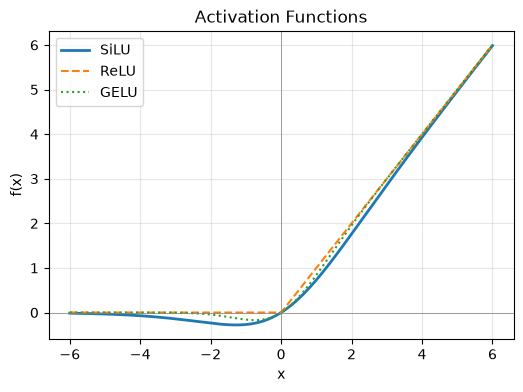

In [5]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-6, 6, 400)

silu = x / (1 + np.exp(-x))
relu = np.maximum(0, x)
gelu = 0.5 * x * (1 + np.tanh(np.sqrt(2/np.pi) * (x + 0.044715 * x**3)))

plt.figure(figsize=(6, 4))
plt.plot(x, silu, label='SiLU', lw=2)
plt.plot(x, relu, '--', label='ReLU')
plt.plot(x, gelu, ':', label='GELU')
plt.axhline(0, color='gray', lw=0.5)
plt.axvline(0, color='gray', lw=0.5)
plt.grid(alpha=0.3)
plt.legend()
plt.title('Activation Functions')
plt.xlabel('x'); plt.ylabel('f(x)')
plt.show()

## Norm：LayerNorm和RMSNorm

Norm 层对激活值做缩放，**把数值拉回到一个稳定的量级**，让训练更稳、更快、更容易收敛。

> Norm 不是为了让数据变成标准正态分布。

### Pre-LayerNorm和Post-LayerNorm
| 架构类型 | 数学表达 | 归一化位置 |
| :--- | :--- | :--- |
| **Post-LN** (原始Transformer) | $x \leftarrow \text{Norm}(x + \text{Sublayer}(x))$ | 在**残差连接之后**进行归一化。 |
| **Pre-LN** (现代主流) | $x \leftarrow x + \text{Sublayer}(\text{Norm}(x))$ | 在**子层（Sublayer）之前**进行归一化。 |
